# Sampler interface

This notebook provides the interface with `Cobaya` to run an MCMC parameter inference on the mock datasets generated with `horizon`.

## Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from chainconsumer import Chain, ChainConsumer, PlotConfig

from tools.utilities import Utilities

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})

green        = ['#a6dba0','#5aae61','#1b7837']
purple       = ['#c2a5cf', '#9970ab', '#762a83']
analogous    = ['#a0c3db', '#dbb7a0']
warm         = ['#fdcc8a', '#fc8d59', '#d7301f']
cool         = ['#41b6c4', '#2c7fb8', '#253494']

### Detect settings from datafile

In [2]:
# find all datasets
datasets, unmatched = Utilities.list_mock_datasets()

# show them
Utilities.print_mock_datasets(datasets, unmatched)

[0] M2 α=-0.085 β=-0.01 n_QSO=100
[1] M2 α=-0.085 β=-0.01 n_QSO=200


In [3]:
# select by index in the list above, returns a dictionary of that dataset's settings
dataset = Utilities.select_mock_dataset(index=1, datasets=datasets)

### Run Cobaya

In [4]:
from cobaya.run import run
from likelihood import DDRlike

info = {
    'params': {
        'alpha': {
            'prior': {'min': -0.2, 'max': 0.2},
            'ref': {'dist': 'norm', 'loc': dataset['alpha'], 'scale': 0.1},
            'proposal': 0.05,
            'latex': r'\alpha'
        },
        'beta': {
            'prior': {'min': -0.1, 'max': 0.1},
            'ref': {'dist': 'norm', 'loc': 0.0, 'scale': 0.02},
            'proposal': 0.001,
            'latex': r'\beta'
        },
    },
    'sampler': {
        'mcmc': {'max_tries': 10000, 'Rminus1_stop': 0.1}
    },
    'output': 'chains/' + dataset['settings'],
    'likelihood': {
        'DDRlike': {
            'external': DDRlike,
            'model': 2,  
            'datapath': './mock_data/' + dataset['settings']
        }
    },
    'force': True
}

info['debug'] = False

# Run MCMC sampling
updated_info, sampler = run(info)

[output] Output to be read-from/written-into folder 'chains', with prefix 'M2alpha-0.085beta-0.01nQSO200'
[output] Found existing info files with the requested output prefix: 'chains/M2alpha-0.085beta-0.01nQSO200'
[output] Will delete previous products ('force' was requested).
[mcmc] Getting initial point... (this may take a few seconds)
[mcmc] Initial point: alpha:-0.1695315, beta:0.003714388
[model] Measuring speeds... (this may take a few seconds)
[model] Setting measured speeds (per sec): {DDRlike: 56700.0}
[mcmc] Covariance matrix not present. We will start learning the covariance of the proposal earlier: R-1 = 30 (would be 2 if all params loaded).
[mcmc] Sampling!
[mcmc] Progress @ 2026-07-01 15:51:12 : 1 steps taken, and 0 accepted.
[mcmc] Learn + convergence test @ 80 samples accepted.
[mcmc]  - Acceptance rate: 0.089
[mcmc]  - Convergence of means: R-1 = 0.618557 after 64 accepted steps
[mcmc]  - Updated covariance matrix of proposal pdf.
[mcmc] Learn + convergence test @ 160 

### Plot contours with chainconsumer

Available columns: ['weight', 'minuslogpost', 'alpha', 'beta', 'minuslogprior', 'minuslogprior__0', 'chi2', 'chi2__DDRlike']
Chain shape: (480, 8)



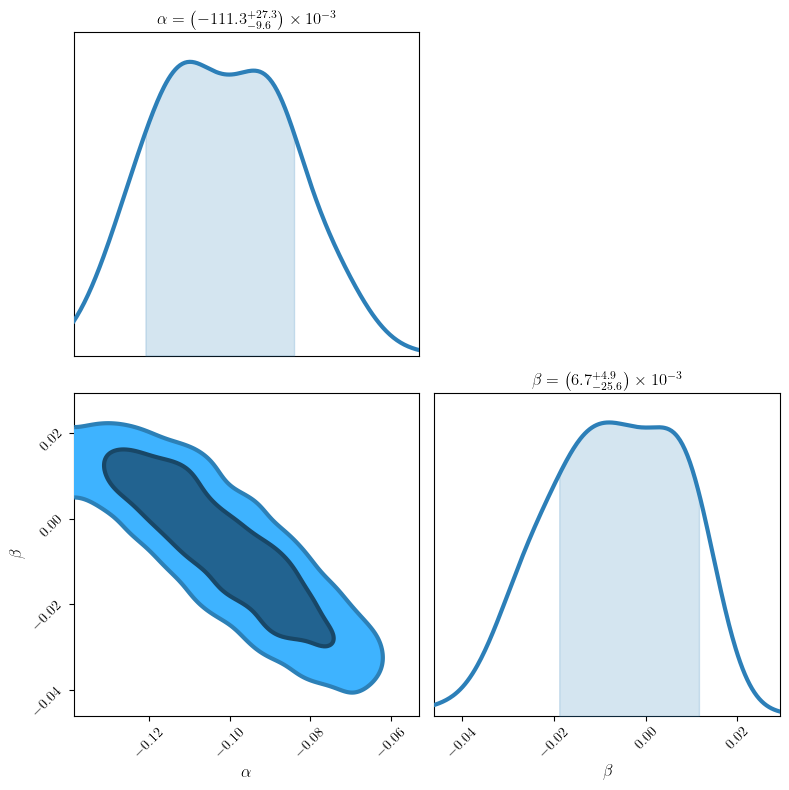

In [5]:
# Read the chain file from Cobaya output
chain_file = 'chains/' + dataset['settings'] + '.1.txt'

# Read the header line to get column names
with open(chain_file, 'r') as f:
    header_line = f.readline()

# Extract column names from the header (remove # and split)
column_names = header_line.strip().lstrip('#').split()

# Read the chain data with explicit column names
df = pd.read_csv(chain_file, sep=r'\s+', comment='#', names=column_names, header=None)

# Print available columns for debugging
print("Available columns:", df.columns.tolist())
print(f"Chain shape: {df.shape}\n")

# Specify the columns to pull for the triangle plot
params = ['alpha', 'beta']

# In ChainConsumer, all data, weights, and styling go into the Chain object
chain_data = Chain(
    samples=df[params],         # Sliced DataFrame directly keeps parameter names
    weights=df['weight'].values,
    name="DDR",
    smooth=20,
    bins=10,
    linewidth=3,
    color=cool[1]               # Uses your color variable
)

# Create ChainConsumer object and add our configured chain
c = ChainConsumer()
c.add_chain(chain_data)

# Set the plot configuration (labels, text style, etc.) using PlotConfig
c.set_plot_config(
    PlotConfig(
        labels={
            'alpha': r'$\alpha$', 
            'beta': r'$\beta$', 
        },
        usetex=True,
        serif=True
    )
)

# FIXED LINE: Accessing the plotting interface via the version-safe .plotter route
fig = c.plotter.plot(figsize=(8, 8))

# Adjust layout for better display
plt.tight_layout()
plt.show()

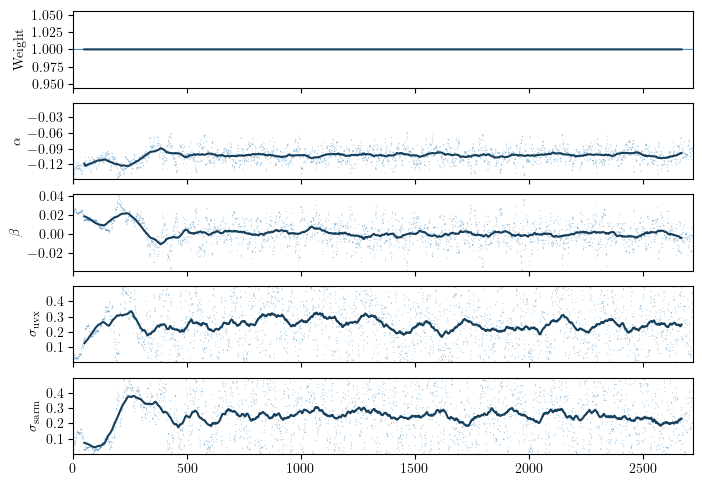

In [6]:
fig = c.plotter.plot_walks(convolve=100)